# Suivi hiérarchique de structures convectives : exemple

Test des algorithmes de `src.tracking` sur 3 pas de temps d'un fichier MesoNH.

- **Fourni par `src/tracking`** : le détecteur générique (`detect_objects`), le moteur (`HierarchicalTrackingEngine`, `TrackingLevel`) et le suivi (`AdvectedIoUTracker`).
- **Défini ici (exemple)** : les paramètres, les règles de détection de chaque niveau (`examples/convective_rules.py`) et la hiérarchie de niveaux.

In [44]:
%matplotlib inline

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import HTML
from matplotlib.animation import FuncAnimation
from skimage.segmentation import find_boundaries

# `src` doit être importable que le notebook soit lancé depuis la racine ou depuis examples/
repo_root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo_root))

from examples.convective_rules import convective_rules
from src.tracking import AdvectedIoUTracker, HierarchicalTrackingEngine, TrackingLevel, detect_objects

## 1. Données (3 pas de temps)

In [45]:
NETCDF_PATH = os.environ.get(
    "NETCDF_PATH",
    "/home/ricj/Documents/Meso-nh/mesochain/learning/cnn/DATA/MesoNH-ice3_CADDIWAF7_1km.nc",
)
N_TIMES = 3

ds = xr.open_dataset(NETCDF_PATH)
if "time" in ds.dims:
    frames = [ds.isel(time=i) for i in range(min(N_TIMES, ds.sizes["time"]))]
else:
    frames = [ds]

time_values = [str(f["time"].values).split("T")[-1].split(".")[0] for f in frames]
timestamps_s = [float(pd.Timestamp(f["time"].values).timestamp()) for f in frames]
print(f"{len(frames)} pas de temps : {time_values}")

3 pas de temps : ['08:00:00', '08:00:30', '08:01:00']


## 2. Paramètres et niveaux

`convective_rules(PARAMS)` transforme les variables et les seuils de `PARAMS` en une règle de détection par niveau (liste des clés d'une règle dans `src/tracking/detection.py`). Un même détecteur générique, `detect_objects`, est utilisé pour tous les niveaux.

In [46]:
PARAMS = {
    # Grille et colonne verticale
    "dx_km": 1.0,
    "min_alt_km": 0.0,
    "max_alt_km": 20.0,
    # Variables
    "wt_var": "WT",
    "ut_var": "UT",
    "vt_var": "VT",
    "mri_var": "MRI",
    "mrc_var": "MRC",
    "mrs_var": "MRS",
    "mrg_var": "MRG",
    "mrr_var": "MRR",
    "tb_var": "MSG2_IR108",
    # MCS : un germe = un MCS (watershed 2D sur Tb)
    "tb_env_k": 230.0,        # enveloppe : Tb <= tb_env_k (étendue maximale d'un MCS)
    # "tb_seed_h_k": 5.0,   # option du nouvel algo (absente de l'ancien) : profondeur minimale (K) d'un minimum de Tb pour être un germe ; plus grand = moins de MCS
    "tb_seed_pct": 0.1,      # germes = percentile (%) de Tb dans l'enveloppe (comme l'ancien code)
    "mcs_min_area_km2": 100.0,  # les MCS plus petits sont écartés
    # Objets convectifs
    "w_thresh": 1.0,
    "hydro_min_gkg": 0.01,
    # Cœurs
    "core_w_thresh": 4.0,
}

Hiérarchie :

- `mcs` est un niveau **racine** ;
- `convective_object` est **enfant de `mcs`** : ses objets sont cherchés dans l'empreinte d'un MCS ;
- `core` est **enfant de `convective_object`** : ses cœurs sont cherchés dans un objet convectif.

Chaque niveau a son propre suivi (`AdvectedIoUTracker`).

In [47]:
def tracker(prefix, index_key, **kwargs):
    return AdvectedIoUTracker(track_prefix=prefix, index_key=index_key, dx_meters=PARAMS["dx_km"] * 1000.0, **kwargs)


rules = convective_rules(PARAMS)
levels = [
    TrackingLevel("mcs", detect_objects, parent_name=None, params=rules["mcs"],
                  tracker=tracker("mcs", "indices_2d", min_score=0.01, patience=4, max_speed_ms=30.0)),
    TrackingLevel("convective_object", detect_objects, parent_name="mcs", params=rules["convective_object"],
                  tracker=tracker("co", "indices_3d", min_score=0.1, patience=2, pre_filter_pixels=60.0)),
    TrackingLevel("core", detect_objects, parent_name="convective_object", params=rules["core"],
                  tracker=tracker("core", "indices_3d", min_score=0.1, pre_filter_pixels=30.0)),
]
level_names = [lvl.name for lvl in levels]

### Figure 1 : hiérarchie

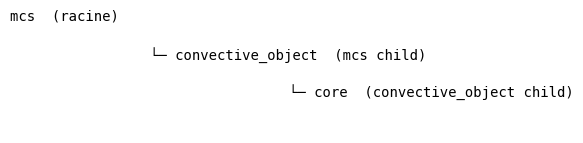

In [48]:
def depth(level):
    parent = {lvl.name: lvl for lvl in levels}.get(level.parent_name)
    return 0 if parent is None else 1 + depth(parent)


fig, ax = plt.subplots(figsize=(6, 1.6))
ax.axis("off")
for i, lvl in enumerate(levels):
    role = "racine" if lvl.parent_name is None else f"{lvl.parent_name} child"
    ax.text(0.03 * depth(lvl) * 10, 1 - 0.3 * i, f"{'└─ ' if lvl.parent_name else ''}{lvl.name}  ({role})",
            va="top", family="monospace")
ax.set_ylim(0, 1)
plt.show()

## 3. Détection et suivi

In [49]:
engine = HierarchicalTrackingEngine(levels)
result = engine.run_and_track(datasets=frames, time_values=time_values, timestamps_s=timestamps_s)
results, tracks = result["results_by_time"], result["tracks_by_level"]

pd.DataFrame(
    {name: [len(step["levels"][name]) for step in results] for name in level_names},
    index=pd.Index(time_values, name="time"),
).assign(**{f"suivis {n}": [len(tracks[n])] * len(results) for n in level_names})

,mcs,convective_object,core,suivis mcs,suivis convective_object,suivis core
time,,,,,,
08:00:00,4,89,155,7,124,203
08:00:30,3,93,157,7,124,203
08:01:00,2,80,146,7,124,203


### Figure 2 : objets détectés au premier pas de temps

Un panneau par niveau, un objet par couleur, contours noirs. Les objets convectifs sont ceux de l'empreinte des MCS, les cœurs sont ceux de l'intérieur des objets convectifs.

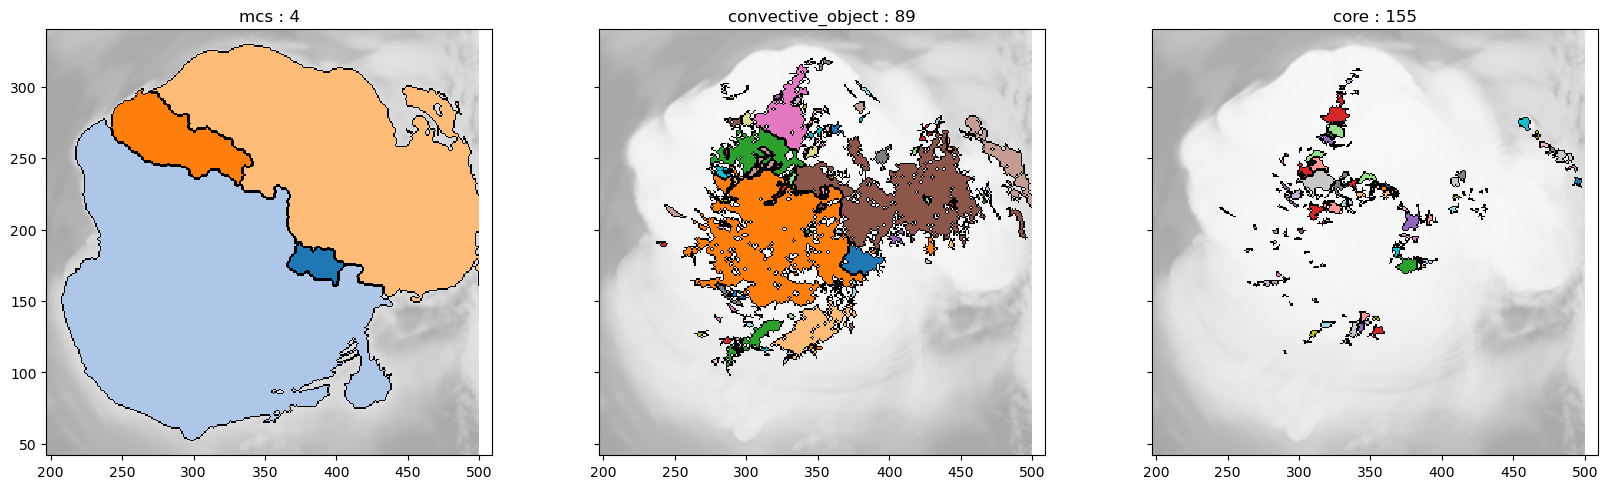

In [50]:

def plot_detection(t):
    tb = tb_of(t)
    fig, axs = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
    for ax, lvl in zip(axs, levels):
        objs = results[t]["levels"][lvl.name]
        own = {o["object_id"]: i for i, o in enumerate(objs, 1)}
        labels = object_image(tb.shape, objs, lambda o: own[o["object_id"]])
        ax.imshow(tb, origin="lower", cmap="gray_r", alpha=0.35)
        ax.imshow(colored(labels), origin="lower", **COLOR)
        ax.imshow(np.ma.masked_equal(find_boundaries(labels, mode="inner"), 0), origin="lower", cmap="gray_r",
                  vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(f"{lvl.name} : {len(objs)}")
    axs[0].set_xlim(VIEW[1].start, VIEW[1].stop)
    axs[0].set_ylim(VIEW[0].start, VIEW[0].stop)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


plot_detection(0)

## 4. Suivi temporel (animation)

La couleur d'un objet est celle de sa **trajectoire** : un même objet garde la même couleur d'un pas de temps à l'autre.

In [51]:
from src.old.fct_core_tracking import find_convective_cores_3d

if "tb_seed_h_k" in PARAMS:
    print("Attention : tb_seed_h_k n'existe pas dans l'ancien code, les MCS ne seront pas identiques.")

old = [
    find_convective_cores_3d(
        f,
        wt_var=PARAMS["wt_var"], ut_var=PARAMS["ut_var"], vt_var=PARAMS["vt_var"],
        mri_var=PARAMS["mri_var"], mrc_var=PARAMS["mrc_var"], mrs_var=PARAMS["mrs_var"],
        mrg_var=PARAMS["mrg_var"], mrr_var=PARAMS["mrr_var"], tb_var=PARAMS["tb_var"],
        w_thresh=PARAMS["w_thresh"],
        min_alt_km=PARAMS["min_alt_km"], max_alt_km=PARAMS["max_alt_km"],
        tb_seed_pct=PARAMS.get("tb_seed_pct"), tb_seed_k=PARAMS.get("tb_seed_k", 190.0),
        tb_env_k=PARAMS["tb_env_k"], hydro_min_gkg=PARAMS["hydro_min_gkg"],
        mcs_min_area_km2=PARAMS["mcs_min_area_km2"],
    )[0]
    for f in frames
]

# Nouveaux détecteurs, mêmes niveaux racines que l'ancien code
flat_levels = [
    TrackingLevel("mcs", detect_objects, parent_name=None, params=rules["mcs"]),
    TrackingLevel("convective_object", detect_objects, parent_name=None, params=rules["convective_object"]),
    TrackingLevel("core", detect_objects, parent_name="convective_object", params=rules["core"]),
]
new_flat = HierarchicalTrackingEngine(flat_levels).run(frames, time_values)


def footprints(objs, key):
    return {frozenset(map(tuple, o[key])) for o in objs}


rows = []
for t in range(len(frames)):
    for name, old_key, idx_key in (("mcs", "mcs", "indices_2d"),
                                   ("convective_object", "conv_objects", "indices_3d"),
                                   ("core", "cores", "indices_3d")):
        o, n = old[t][old_key], new_flat[t]["levels"][name]
        rows.append({
            "time": time_values[t], "niveau": name,
            "ancien": len(o), "nouveau": len(n),
            "identiques": footprints(o, idx_key) == footprints(n, idx_key),
            "hiérarchie": len(results[t]["levels"][name]),
        })
comparison = pd.DataFrame(rows).set_index(["time", "niveau"])
comparison

ancien  nouveau  identiques  hiérarchie
time     niveau                                                    
08:00:00 mcs                     4        4        True           4
         convective_object      90       90        True          89
         core                  148      148        True         155
08:00:30 mcs                     3        3        True           3
         convective_object     100      100        True          93
         core                  151      151        True         157
08:01:00 mcs                     2        2        True           2
         convective_object      96       96        True          80
         core                  151      151       False         146

In [52]:
ds.close()